# Arron Driven with LightBGM

### 2.1 Overview

- The Aroon Indicator with LightGBM Strategy is a trend-following approach using the Aroon

- Indicator and a LightGBM classifier to predict trend direction. A bullish signal triggers a

- long position when Aroon Up > Aroon Down with LightGBM uptrend probability > 0.7. A

- bearish signal triggers a short position when Aroon Down > Aroon Up. ATR sets TP/SL levels,
optimized for 1-minute candles with 5x leverage.

### 2.2.1 Signal Generation

- • Bullish: Aroon Upt > Aroon Downt, LightGBM uptrend probability > 0.7. Triggers long•

- • Bearish: Aroon Downt > Aroon Upt, LightGBM downtrend probability > 0.7. Triggers short.

- • Example: Price = $100, Aroon Up = 70, Aroon Down = 30, LightGBM = 0.75
0.75. Open long.


### 2.4.1 Model Type

- LightGBM classifier with 100 trees, implemented using the LightGBM library, predicts Aroon trend signals


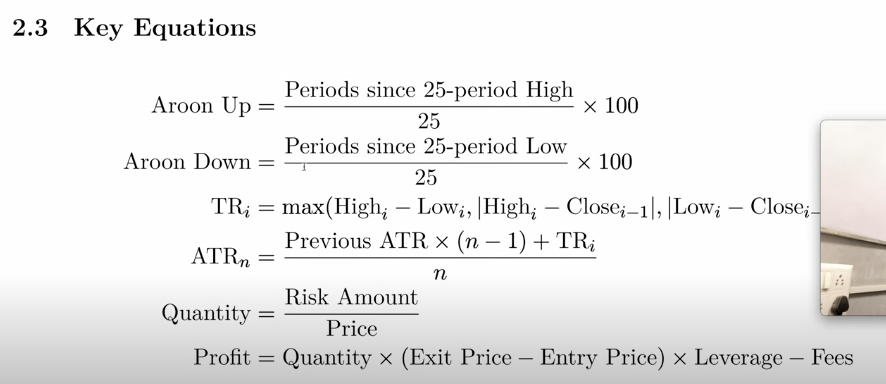

In [10]:
import ccxt.async_support as ccxt
import pandas as pd
import numpy as np
import asyncio
import nest_asyncio
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
import logging

logging.basicConfig(level = logging.INFO , format = '%(asctime)s - %(message)s')
logger = logging.getLogger(__name__)
nest_asyncio.apply()
                    
                    
                

In [12]:
SYMBOL = 'ALCH/USDT'
TIMEFRAME = '1m'
RISK_AMOUNT = 10.0
LEVERAGE = 5
AROON_PERIOD = 25
ATR_PERIOD = 14
TP_MULTIPLIER = 2.0
SL_MULTIPLIER = 1.0
FEE_RATE = 0.0002
MAX_POSITIONS = 2
CHECK_INTERVAL = 60 
MODEL_THRESHOLD = 0.7

open_positions = []
model = lgb.LGBMClassifier(n_estimators = 100 , random_state = 42)
scaler = StandardScaler()


In [14]:
async def fetch_data(exchange , symbol :str  , timeframe : str , limit : int = 100) -> pd.DataFrame:
    try:
        ohlcv = await exchange.fetch_ohlcv(symbol , timeframe , limit = limit)
        df = pd.DataFrame(ohlcv , columns = ['timestamp' , 'open' , 'high','low','close','volume'])
        df['timestamp'] = pd.to_datetime(df['timestamp'] , unit = 'ms')
        return df
    except Exception as e:
        logger.error(f"Error Fetching data: {str(e)}")
        return pd.DataFrame

In [16]:
def calculate_indicators(df : pd.DataFrame) -> pd.DataFrame:
    try:
        df['aroon_up'] = ((AROON_PERIOD - df['high'].rolling(AROON_PERIOD).
                          apply(lambda x : np.argmax(x))) / AROON_PERIOD) * 100
        df['aroon_down'] = ((AROON_PERIOD - df['low'].rolling(AROON_PERIOD).
                          apply(lambda x : np.argmin(x))) / AROON_PERIOD) * 100

        # ATR
        df['tr'] = pd.concat([df['high'] - df['low'],
                             (df['high'] - df['close'].shift()).abs(),
                             (df['low'] - df['close'].shift()).abs()],
                            axis = 1).max(axis = 1)
        df['atr'] = df['tr'].rolling(ATR_PERIOD).mean()

        # Features
        df['price_change'] = df['close'].pct_change()
        df['aroon_diff'] = df['aroon_up'] - df['aroon_down']
        return df
    except Exception as e:
        logger.error(f"Error calculating the Indiactors: {str(e)}")
        return df
        
        

In [18]:
def train_model(df: pd.DataFrame) -> None:
    try:
        features = ['price_change' , 'aroon_diff' , 'atr']
        X = df[features].dropna()
        y = (df['aroon_up'].shift(-1) > df['aroon_down'].shift(-1)).astype(int)[X_index]
        if len(X) < 10:
            return 
        X_scaled = scaler.fit_transform(X)
        model.fit(X_scaled , y)
    except Exception as e:
        logger.error(f"Error training model: {str(e)}")
        

In [20]:
def get_aroon_signal(df : pd.DataFrame) -> str:
    try:
        aroon_up = df['aroon_up'].iloc[-1]
        aroon_down = df['aroon_down'].iloc[-1]
        if pd.isna([aroon_up , aroon_down]).any():
            return 'neutral'
        features = ['price_change' , 'aroon_diff' , 'atr']
        X = df[features].iloc[-1:].dropna()
        if X.empty:
            return 'neutral'
        X_scaled = scaler.transform(X)
        prob = model.predict_proba(X_scaled)[0]
        if aroon_up > aroon_down and prob[1] > MODEL_THRESHOLD:
            return 'bullish'
        elif aroon_down > aroon_up and prob[0] > MODEL_THRESHOLD:
            return 'bearish'
        return 'neutral'
    except Exception as e:
        logger.error(f"Error in signal generation: {str(e)}")
        return 'neutral'
        

In [22]:
async def manage_positions(exchange , current_price : float ):
    global open_positions
    positions_to_remove = []
    try:
        for pos in open_positions:
            entry_price = pos['entry_price']
            qty = pos['quantity']
            side = pos['side']
            tp_price = pos['tp_price']
            sl_price = pos['sl_price']
            if side == 'long':
                if current_price >= tp_price:
                    logger.info(f"[check mark] Long TP hit at {current_price: .2f} , Profit:{(current_price - entry_price) * qty *  LEVERAGE:.2f}")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
                elif current_price <= sl_price:
                    logger.info(f"[cross mark] Long SL hit at {current_price: .2f} , Loss: {(entry_price - current_price) * qty *  LEVERAGE:.2f }")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
            else:
                if current_price <= tp_price:
                    logger.info(f"[check mark] Short TP hit at {current_price: .2f} , Profit: {( entry_price - current_price) * qty *  LEVERAGE:.2f }")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
                elif current_price >= sl_price:
                    logger.info(f"[cross mark] Short SL hit at {current_price: .2f} , Loss:{(current_price - entry_price) * qty  * LEVERAGE:.2f }")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
        open_positions = [pos for pos in open_positions if pos not in positions_to_remove]
    except Exception as e:
        logger.error(f"Error managing the Positions: {str(e)}")

                
                    

In [24]:
async def place_order(exchange , signal: str , price : float , atr:float ):
    try:
        if len(open_positions) >= MAX_POSITIONS:
            logger.info("Max positions reached, skipping new order")
            return
        qty = RISK_AMOUNT / price
        if signal == 'bullish':
            order = await exchange.create_market_buy_order(SYMBOL ,qty )
            tp_price = price + TP_MULTIPLIER * atr;
            sl_price = price - SL_MULTIPLIER * atr;
            open_positions.append({
                'symbol' :SYMBOL , 
                'side' : 'long',
                'entry_price' : price,
                'quantity' : qty,
                'tp_price' : tp_price , 
                'sl_price' : sl_price
            })
            logger.info(f"[char increasing] Opened long at {price:. 2f} , Qty: {qty:.4f} , TP: {tp_price:. 2f} , SL: {sl_price:. 2f}")
        elif signal == 'bearsih':
            order = await exchange.create_market_sell_order(SYMBOL ,qty )
            tp_price = price - TP_MULTIPLIER * atr;
            sl_price = price + SL_MULTIPLIER * atr;
            open_positions.append({
                'symbol' : SYMBOL , 
                'side' : 'short',
                'entry_price' : price,
                'quantity' : qty,
                'tp_price' : tp_price , 
                'sl_price' : sl_price
            })
            logger.info(f"[char increasing] Opened short at {price:. 2f} , Qty: {qty:.4f} , TP: {tp_price:. 2f} , SL: {sl_price:. 2f}")
    except Exception as e:
        logger.error(f"Error placing order: {str(e)}")
            
            
            

In [26]:
async def main():
    try:
        exchange = ccxt.binance({
            'enableRateLimit': True,
            'apiKey': 'your_api_key',
            'secret': 'your-api_secret',
            'enabledLeverage' : True
        })
        await exchange.load_markets()
        await exchange.set_leverage(LEVERAGE , SYMBOL1)
        df_initial = await fetch_data(exchange , SYMBOL , TIMEFRAME ,limit = 500)
        if not df_initial.empty:
            df_initial = calculate_indicators(df_initial)
            train_model(df_initial)
        while True:
            try:
                df = await fetc_data(exchange , SYMBOL , TIMEFRAME )
                if df.empty:
                    await asyncio.sleep(CHECK_INTERVAL)
                    continue
                df = calculate_indicators(df)
                current_price = df['close'].iloc[-1]
                atr = df['atr'].iloc[-1]
                signal = get_aroon_signal(df)
                await manage_positions(exchange , current_price)
                if signal != 'neutral':
                    await place_order(exchange , signal , current_price , atr )
                logger.info(f"Price: {current_price:.2f} , +VI: {df["plus_vi"].iloc[-1]:.2f} , -VI: {df['minus_vi'].iloc[-1]:.2f}, Signal: {signal}")
                if len(df) >= 500:
                    train_model(df)
                await asyncio.sleep(CHECK_INTERVAL)
            except Exception as e:
                logger.error(f"Error in main loop: {str(e)}")
                await asyncio.sleep(CHECK_INTERVAL)
    except Exception as e:
        logger.error(f"Error initializing exchange: {str(e)}")
    finally:
        await exchange.close()
        

In [28]:
if __name__ == '__main__':
    asyncio.get_event_loop().run_until_complete(main())
    

2025-06-19 13:38:53,579 - Error initializing exchange: binance {"code":-2008,"msg":"Invalid Api-Key ID."}
